# Extension B: The virtual spectrometer (colours, prism, polarisation filters)

**Goal.** Take the Zeeman lines computed in Levels 1 to 4 and put real optics in front of them:
see their colours, split light with a prism, and filter by polarisation, one component at a time.

**The chain.** source in a field $B$, then a line of sight at angle $\theta$ from $B$, then a polariser or
analyser, then a prism (colours) and/or a high-resolution stage (Zeeman components).

**An honest scale note.** A Zeeman shift is tiny: the outermost sodium D2 component moves only
about 27 pm per tesla. All the components are the *same yellow*. We will see that a prism cannot
separate them and exactly how fine an instrument has to be. Plots draw the colour of the light on a
yellow strip along the axis so the scale stays honest.

Colour of sodium D light (589 nm), RGB = (1.0, 0.88, 0.0)
    name element  wavelength_nm  intensity               rgb
Hg 404.7      Hg        404.660       0.40 (0.51, 0.0, 0.78)
 H-delta       H        410.170       0.25 (0.49, 0.0, 0.86)
 H-gamma       H        434.050       0.45  (0.16, 0.0, 1.0)
Hg 435.8      Hg        435.830       0.90  (0.12, 0.0, 1.0)
  H-beta       H        486.130       0.70  (0.0, 0.94, 1.0)
Hg 546.1      Hg        546.070       1.00  (0.59, 1.0, 0.0)
Hg 577.0      Hg        576.960       0.50  (0.97, 1.0, 0.0)
Hg 579.1      Hg        579.070       0.55  (0.99, 1.0, 0.0)
   Na D2      Na        588.995       0.90  (1.0, 0.89, 0.0)
   Na D1      Na        589.592       0.60  (1.0, 0.88, 0.0)
 H-alpha       H        656.280       1.00   (1.0, 0.0, 0.0)


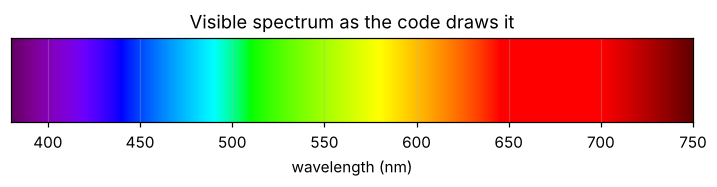

In [1]:
import sys
sys.path.insert(0, '..')          # so `import src...` works from the notebooks folder
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
import pandas as pd
from src.optics.color import wavelength_to_rgb, rainbow_strip
from src.optics.prism import refractive_index, deviation_deg, min_deviation_deg, screen_position_m
from src.optics.spectrometer import (sodium_d_components, observe, required_resolving_power,
                                     LAMP_LINES, vacuum_cm1_to_air_nm)

plt.figure(figsize=(8, 1))
plt.imshow(rainbow_strip(380, 750, 600, 30), aspect='auto', extent=[380, 750, 0, 1])
plt.yticks([]); plt.xlabel('wavelength (nm)'); plt.title('Visible spectrum as the code draws it'); plt.show()

print('Colour of sodium D light (589 nm), RGB =', tuple(round(c, 2) for c in wavelength_to_rgb(589.3)))
print(LAMP_LINES.assign(rgb=[tuple(round(c, 2) for c in wavelength_to_rgb(w)) for w in LAMP_LINES.wavelength_nm]).to_string(index=False))

## Glass bends colours differently

A prism works because the refractive index depends on wavelength. The code uses the Sellmeier
equation with catalogue constants for two glasses:

In [2]:
wl = np.array([404.7, 486.1, 546.1, 589.3, 656.3])
tab = pd.DataFrame({'wavelength (nm)': wl,
                    'n (BK7)': refractive_index(wl, 'BK7'),
                    'n (SF11)': refractive_index(wl, 'SF11')}).round(5)
print(tab.to_string(index=False))
print()
print('BK7 index at the d line (587.6 nm): %.5f  (catalogue 1.5168)' % refractive_index(587.56, 'BK7'))
print('Minimum deviation of a 60 deg SF11 prism at 589 nm: %.2f deg' % min_deviation_deg(589.3, 60, 'SF11'))

 wavelength (nm)  n (BK7)  n (SF11)
           404.7  1.53023   1.84232
           486.1  1.52238   1.80652
           546.1  1.51872   1.79191
           589.3  1.51673   1.78446
           656.3  1.51432   1.77595

BK7 index at the d line (587.6 nm): 1.51680  (catalogue 1.5168)
Minimum deviation of a 60 deg SF11 prism at 589 nm: 66.31 deg


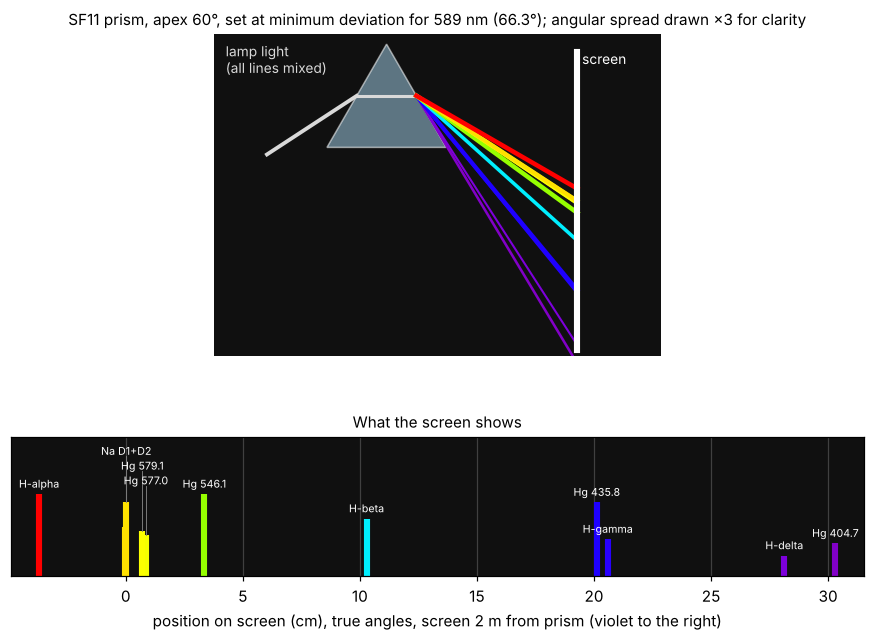

In [3]:
from src.optics.figures import fig_prism_setup
fig_prism_setup(); plt.show()

Violet bends most, red least. The lower panel shows what a screen 2 m away would show for a lamp with
sodium, mercury and hydrogen lines: well separated colours, but the sodium D1 and D2 lines sit almost on
top of each other because they are only 0.6 nm apart.

## Why a prism cannot show the Zeeman components

Compare how far apart things land on the screen, in micrometres:

In [4]:
c = sodium_d_components(1.0)                                   # B = 1 tesla
x_um = screen_position_m(c.wavelength_nm.to_numpy(), 2.0, glass='SF11') * 1e6
d2 = c.line == 'D2'
print('Na D2 components at 1 T, spread on a screen 2 m away (SF11 prism): %.1f micrometres' % (np.ptp(x_um[d2])))
sep = screen_position_m(float(vacuum_cm1_to_air_nm(16956.17)), 2.0, glass='SF11') - screen_position_m(float(vacuum_cm1_to_air_nm(16973.37)), 2.0, glass='SF11')
print('Na D1 vs D2 (0.6 nm apart):                                       %.1f micrometres' % (abs(sep) * 1e6))
print()
airy_um = 1.22 * 589.3e-9 * 2.0 / 0.01 * 1e6          # diffraction-limited spot of a 1 cm beam focused at 2 m
print('Smallest focused spot of a 1 cm wide beam at 2 m (diffraction limit): about %.0f micrometres' % airy_um)
print()
print('The whole D2 Zeeman pattern is spread over less than that spot, so the components blur together.')
print('A prism of this kind cannot show them; a finer instrument is needed.')

Na D2 components at 1 T, spread on a screen 2 m away (SF11 prism): 36.3 micrometres
Na D1 vs D2 (0.6 nm apart):                                       400.5 micrometres

Smallest focused spot of a 1 cm wide beam at 2 m (diffraction limit): about 144 micrometres

The whole D2 Zeeman pattern is spread over less than that spot, so the components blur together.
A prism of this kind cannot show them; a finer instrument is needed.


## The instrument ladder

Resolving power $R=\lambda/\Delta\lambda$ says how fine an instrument can see. The closest sodium Zeeman
components need a certain $R$ at each field; instruments provide a certain $R$. Where they meet is the
weakest field at which the pattern is visible:

Resolving power needed to separate the closest Zeeman components of Na:
  B =  0.1 T : R =   546474
  B =  0.5 T : R =   109698
  B =  1.0 T : R =    55106
  B =  2.0 T : R =    27816
  B =  5.0 T : R =    11466

                         instrument  ideal R  weakest resolvable field (T)
             Prism (BK7, 5 cm base)     2073                        26.300
            Prism (SF11, 5 cm base)     7568                         7.204
           Grating (600 l/mm, 5 cm)    30000                         1.817
   Large grating (1200 l/mm, 10 cm)   120000                         0.454
Fabry-Perot (10 mm gap, finesse 30)  1018157                         0.054


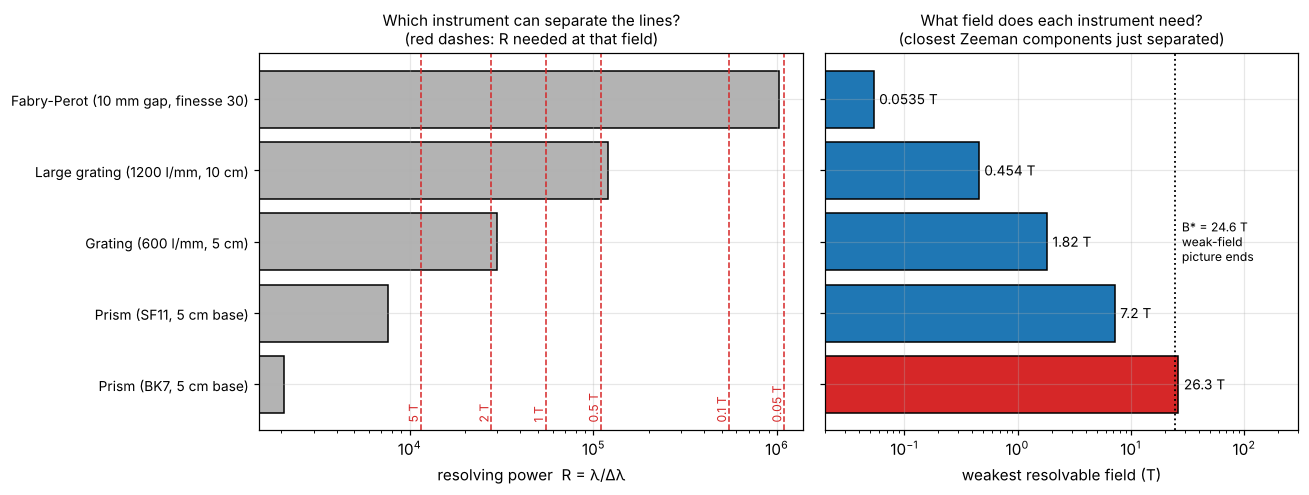

In [5]:
from src.optics.instruments import fig_instrument_ladder, instrument_ladder
from src.optics.spectrometer import field_for_resolving_power

print('Resolving power needed to separate the closest Zeeman components of Na:')
for b in (0.1, 0.5, 1.0, 2.0, 5.0):
    print('  B = %4.1f T : R = %8.0f' % (b, required_resolving_power(sodium_d_components(b))))
print()
rows = [(k, round(v), round(field_for_resolving_power(v), 3)) for k, v in instrument_ladder().items()]
print(pd.DataFrame(rows, columns=['instrument', 'ideal R', 'weakest resolvable field (T)']).to_string(index=False))
fig_instrument_ladder(); plt.show()

**Take-away.** A 5 cm glass prism (R about 2000) would only reveal the pattern at about 25 T, where the weak-field
picture has already broken down. A large grating needs roughly 0.5 T, a Fabry-Perot about 0.05 T. This is why Zeeman
spectroscopy uses high-resolution instruments, and why the spectrum below is drawn in picometres, not as colours.

## Polarisation: what each viewing direction shows

A field-aligned atom radiates three kinds of light. With $q=m_{upper}-m_{lower}$:
$\pi$ ($q=0$) is a dipole along $B$, intensity $\propto\sin^2\theta$; $\sigma^\pm$ ($q=\pm1$) is a dipole rotating around $B$,
intensity $\propto(1+\cos^2\theta)/2$, where $\theta$ is the angle between line of sight and $B$.
Across the field the $\pi$ light is linear along $B$ and the $\sigma$ light linear across it; along the field only
circular $\sigma$ light remains.

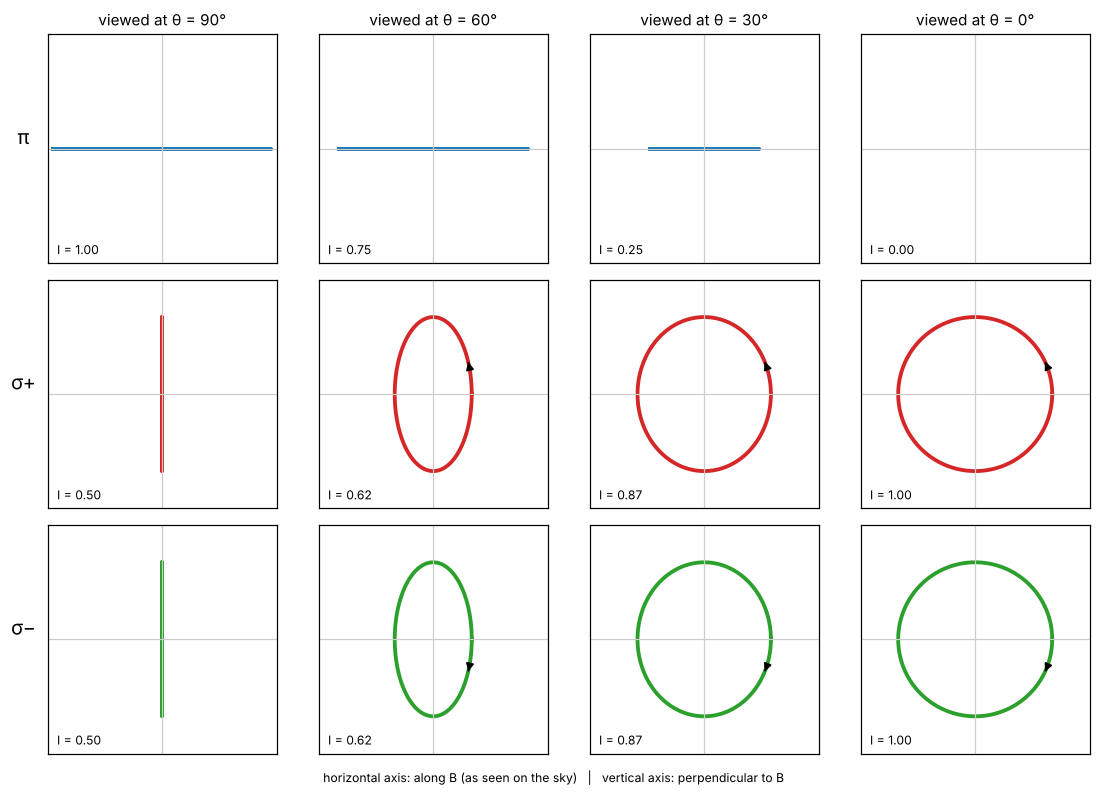

In [6]:
from src.optics.figures import fig_polarisation_ellipses, fig_polarisation_filters
fig_polarisation_ellipses(); plt.show()

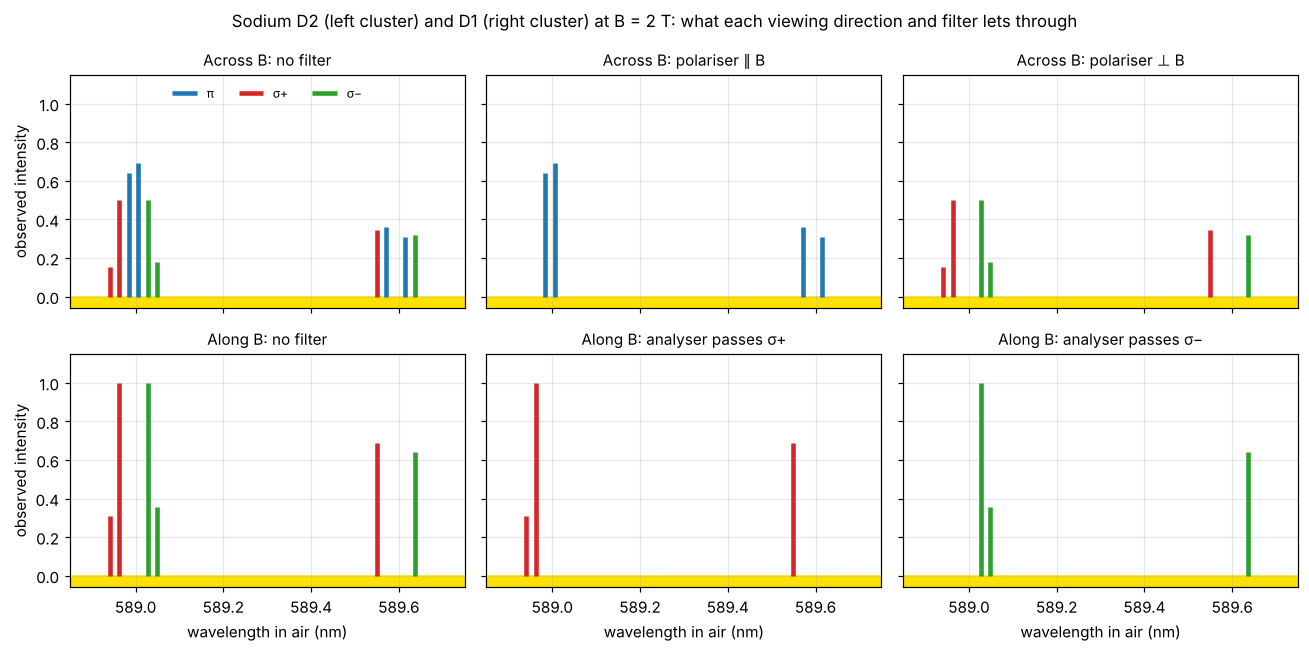

In [7]:
fig_polarisation_filters(2.0); plt.show()

Top row: looking across $B$. A polariser parallel to $B$ keeps only $\pi$ lines; one perpendicular keeps only $\sigma$.
Bottom row: looking along $B$ there are no $\pi$ lines, and a circular analyser (quarter-wave plate plus polariser)
separates $\sigma^+$ (red) from $\sigma^-$ (green).

## Check against the textbook: classic intensity ratios

Viewed across the field in weak field, the four D1 components are equally bright, and the D2 components
have relative intensities 4 : 3 : 1 (the $\pi$ lines : inner $\sigma$ : outer $\sigma$). Nothing here is typed in:
it comes from the matrix elements and the angular pattern.

In [8]:
comps = sodium_d_components(0.05)
seen = observe(comps, 90.0)
d1 = seen[seen.line == 'D1'].observed.to_numpy()
print('D1 observed intensities:', np.round(d1, 3), '  (all equal)')
d2 = seen[seen.line == 'D2'].assign(absshift=lambda d: d.shift_pm.abs()).sort_values('absshift')
pi, s_in, s_out = d2.observed.to_numpy()[[0, 2, 4]]
print('D2: pi : inner sigma : outer sigma = %.2f : %.2f : %.2f' % (pi / s_out, s_in / s_out, 1.0))

D1 observed intensities: [0.333 0.333 0.334 0.334]   (all equal)
D2: pi : inner sigma : outer sigma = 4.00 : 2.99 : 1.00


## Animations

Generated by `scripts/make_optics_figures.py --gif` into `docs/figures/`.

**1. Colour filter scan.** A colour (band-pass) filter sweeps across the lamp spectrum and only the lines inside its
pass band reach the screen. This is "filter each colour one by one".

![filter scan](../docs/figures/optics_filter_scan.gif)

**2. Field ramp.** Raising $B$ makes the Zeeman components of Na D1 and D2 fan out.

![field ramp](../docs/figures/optics_zeeman_field_ramp.gif)

**3. Rotating polariser.** Across the field, $\pi$ and $\sigma$ lines trade places as the polariser turns (Malus's law).

![polariser rotation](../docs/figures/optics_polariser_rotation.gif)

**4. Tilting the line of sight.** From across the field to along it: $\pi$ fades out and $\sigma$ becomes circular.

![view angle](../docs/figures/optics_view_angle.gif)

**Take-away.** Colour tells you the *element* and the *transition*; the Zeeman components live far finer than
the eye or a prism can see; and polarisation is the tool that sorts them: linear filters across the field, circular
filters along it. Together they let you pick out single components and compare their intensities with theory.